# Phone Detection — YOLO11n Fine-Tuning
Fine-tune Ultralytics YOLO11n for the prepared single-class phone dataset. This notebook does not modify or regenerate the dataset. Run the test set only after training and validation/model selection are complete.

In [1]:
from pathlib import Path
import os
import sys
import subprocess

subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics'])

import torch
import yaml
import pandas as pd
import numpy as np
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
    print('CUDA devices:', torch.cuda.device_count())
else:
    print('No CUDA device detected; CPU fallback is enabled.')


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
CUDA devices: 2


## 1. Dataset location
Set `DATASET_OVERRIDE` to an exact `data.yaml` path if Kaggle input names are different. Kaggle input names are never assumed.

In [2]:
DATASET_OVERRIDE = None  # Example: '/kaggle/input/my-dataset/phone_detection/data.yaml'
IS_KAGGLE = Path('/kaggle/input').exists()


def find_local_yaml():
    for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        y = candidate / 'data' / 'processed' / 'phone_detection' / 'data.yaml'
        if y.is_file():
            return y.resolve()
    return None


def find_kaggle_yaml():
    matches = []
    root = Path('/kaggle/input')
    if root.exists():
        for y in root.rglob('data.yaml'):
            try:
                cfg = yaml.safe_load(y.read_text(encoding='utf-8')) or {}
                names = cfg.get('names')
                if cfg.get('nc') == 1 and (names == ['phone'] or names == {0: 'phone'}):
                    matches.append(y.resolve())
            except Exception:
                continue
    return matches


if DATASET_OVERRIDE:
    DATA_YAML = Path(DATASET_OVERRIDE).expanduser().resolve()
elif IS_KAGGLE:
    matches = find_kaggle_yaml()
    if len(matches) == 1:
        DATA_YAML = matches[0]
    elif len(matches) > 1:
        print(*matches, sep='\n')
        raise RuntimeError('Set DATASET_OVERRIDE because multiple phone datasets were found.')
    else:
        raise FileNotFoundError('No phone-only data.yaml found under /kaggle/input.')
else:
    DATA_YAML = find_local_yaml()
    if DATA_YAML is None:
        raise FileNotFoundError('Set DATASET_OVERRIDE to the exact phone data.yaml path.')

DATASET_ROOT = DATA_YAML.parent.resolve()
print('Dataset yaml:', DATA_YAML)
print('Dataset root:', DATASET_ROOT)


Dataset yaml: /kaggle/input/datasets/mohamedmagdyrizk/phone-detection-dataset/phone_detection/data.yaml
Dataset root: /kaggle/input/datasets/mohamedmagdyrizk/phone-detection-dataset/phone_detection


## 2. Dataset verification
Load `data.yaml`, verify exactly one class, all train/val/test paths, image/label pairing, and normalized YOLO coordinates. Negative labels must be empty files.

In [3]:
import pandas as pd

IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}
config = yaml.safe_load(DATA_YAML.read_text(encoding='utf-8'))
if not isinstance(config, dict):
    raise RuntimeError('data.yaml must contain a mapping.')
if config.get('nc') != 1:
    raise RuntimeError(f"Expected nc: 1, got {config.get('nc')}")
if config.get('names') not in (['phone'], {0: 'phone'}):
    raise RuntimeError(f"Expected names ['phone'], got {config.get('names')}")

split_paths = {}
for split in ('train', 'val', 'test'):
    if split not in config:
        raise RuntimeError(f'Missing {split} in data.yaml')
    relative = Path(config[split])
    candidates = [(DATASET_ROOT / relative).resolve(), (DATASET_ROOT / split).resolve(), (DATASET_ROOT / split / 'images').resolve()]
    split_path = next((p for p in candidates if p.is_dir()), None)
    if split_path is None:
        raise FileNotFoundError(f'Could not resolve {split}: {config[split]}')
    split_paths[split] = split_path

stats = []
for split, image_dir in split_paths.items():
    label_dir = DATASET_ROOT / 'labels' / split
    if not label_dir.is_dir():
        raise FileNotFoundError(f'Missing label directory: {label_dir}')
    images = sorted(p for p in image_dir.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
    positive = negative = 0
    for image in images:
        label = label_dir / f'{image.stem}.txt'
        if not label.is_file():
            raise RuntimeError(f'Missing label: {label}')
        text = label.read_text(encoding='utf-8').strip()
        if not text:
            negative += 1
            continue
        positive += 1
        for line_number, line in enumerate(text.splitlines(), 1):
            fields = line.split()
            if len(fields) != 5:
                raise RuntimeError(f'Malformed label: {label}:{line_number}')
            try:
                class_id = int(fields[0])
                values = [float(v) for v in fields[1:]]
            except ValueError as exc:
                raise RuntimeError(f'Invalid label: {label}:{line_number}') from exc
            if class_id != 0:
                raise RuntimeError(f'Unexpected class {class_id} in {label}')
            if not all(0 <= v <= 1 for v in values) or values[2] <= 0 or values[3] <= 0:
                raise RuntimeError(f'Invalid coordinates in {label}:{line_number}')
    stats.append({'Split': split, 'Images': len(images), 'Positive': positive, 'Negative': negative})

print(pd.DataFrame(stats).to_string(index=False))
for split, p in split_paths.items():
    print(split + ':', p)
print('Dataset verification passed.')


Split  Images  Positive  Negative
train   18800      8358     10442
  val    1730       795       935
 test    2349      1102      1247
train: /kaggle/input/datasets/mohamedmagdyrizk/phone-detection-dataset/phone_detection/images/train
val: /kaggle/input/datasets/mohamedmagdyrizk/phone-detection-dataset/phone_detection/images/val
test: /kaggle/input/datasets/mohamedmagdyrizk/phone-detection-dataset/phone_detection/images/test
Dataset verification passed.


## 3. YOLO11n training configuration
YOLO11n is a lightweight pretrained baseline suitable for a first single-class phone detector. Conservative augmentation avoids aggressive distortions of small phone objects.

In [4]:
MODEL_NAME = 'yolo11n.pt'
IMAGE_SIZE = 640
EPOCHS = 100
BATCH_SIZE = 16 if torch.cuda.is_available() else 4
OPTIMIZER = 'AdamW'
LEARNING_RATE = 0.001
PATIENCE = 20
RANDOM_SEED = 42
NUM_WORKERS = 8 if torch.cuda.is_available() else 2
AUGMENTATION = {
    'hsv_h': 0.015, 'hsv_s': 0.5, 'hsv_v': 0.4,
    'degrees': 0.0, 'translate': 0.10, 'scale': 0.50,
    'shear': 0.0, 'perspective': 0.0, 'flipud': 0.0,
    'fliplr': 0.5, 'mosaic': 1.0, 'mixup': 0.0, 'copy_paste': 0.0,
}
DEVICE = '0' if torch.cuda.is_available() else 'cpu'
print({'model': MODEL_NAME, 'image_size': IMAGE_SIZE, 'epochs': EPOCHS,
       'batch': BATCH_SIZE, 'optimizer': OPTIMIZER, 'lr': LEARNING_RATE,
       'patience': PATIENCE, 'seed': RANDOM_SEED, 'device': DEVICE})


{'model': 'yolo11n.pt', 'image_size': 640, 'epochs': 100, 'batch': 16, 'optimizer': 'AdamW', 'lr': 0.001, 'patience': 20, 'seed': 42, 'device': '0'}


## 4. Fine-tune
Training also evaluates on validation. The best and last checkpoints are saved by Ultralytics.

In [5]:
# Write a Kaggle-writable yaml with absolute paths that Ultralytics can resolve
FIXED_YAML = Path('/kaggle/working/phone_data_fixed.yaml') if IS_KAGGLE else DATASET_ROOT / 'data_fixed.yaml'

fixed_cfg = {
    'path': str(DATASET_ROOT),
    'train': str(split_paths['train']),
    'val':   str(split_paths['val']),
    'test':  str(split_paths['test']),
    'nc': 1,
    'names': ['phone'],
}
FIXED_YAML.write_text(yaml.safe_dump(fixed_cfg, sort_keys=False), encoding='utf-8')

DATA_YAML = FIXED_YAML   # training/val/test cells below all use DATA_YAML
print(FIXED_YAML.read_text())

OUTPUT_ROOT = Path('/kaggle/working') if IS_KAGGLE else Path.cwd().resolve()
TRAIN_PROJECT = OUTPUT_ROOT / 'phone_detection_training'
TRAIN_PROJECT.mkdir(parents=True, exist_ok=True)

model = YOLO(MODEL_NAME)
training_results = model.train(
    data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE, device=DEVICE, optimizer=OPTIMIZER,
    lr0=LEARNING_RATE, patience=PATIENCE, seed=RANDOM_SEED,
    workers=NUM_WORKERS, project=str(TRAIN_PROJECT),
    name='yolo11n_phone', exist_ok=True, plots=True,
    save=True, val=True, **AUGMENTATION,
)
TRAIN_RUN_DIR = Path(training_results.save_dir)
print('Training run:', TRAIN_RUN_DIR)


path: /kaggle/input/datasets/mohamedmagdyrizk/phone-detection-dataset/phone_detection
train: /kaggle/input/datasets/mohamedmagdyrizk/phone-detection-dataset/phone_detection/images/train
val: /kaggle/input/datasets/mohamedmagdyrizk/phone-detection-dataset/phone_detection/images/val
test: /kaggle/input/datasets/mohamedmagdyrizk/phone-detection-dataset/phone_detection/images/test
nc: 1
names:
- phone

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/phone_data_fixed.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/100       3.1G      1.748      1.368      1.403         21        640: 100% ━━━━━━━━━━━━ 1175/1175 7.9it/s 2:29
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 55/55 7.9it/s 7.0s
                   all       1730        807      0.665       0.58      0.636      0.351

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/100       3.1G      1.716      1.298      1.378         20        640: 100% ━━━━━━━━━━━━ 1175/1175 7.9it/s 2:28
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 55/55 8.0it/s 6.9s
                   all       1730        807      0.781      0.657      0.744      0.439

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      4/100       3.1G      1.689      1.236      1.365         20        640: 100% ━━━━━━━━━━━━ 1175/1175 8.0it/s 2:26
                 Class     Images  Instances      

## 5. Training and validation curves
Metrics: box loss, classification loss, DFL loss, precision, recall, mAP@50, and mAP@50-95.

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
88,89,14305.0,1.16650,0.56178,1.07622,0.88993,0.86160,0.91793,0.67943,1.00939,0.63266,1.05694,0.000129,0.000129,0.000129
89,90,14460.8,1.17035,0.55624,1.07379,0.88735,0.86369,0.91921,0.67886,1.01147,0.63097,1.05787,0.000119,0.000119,0.000119
90,91,14614.7,1.13577,0.49408,1.08379,0.88815,0.86589,0.91892,0.67839,1.01009,0.63201,1.05676,0.000109,0.000109,0.000109
91,92,14767.0,1.11847,0.47803,1.07656,0.88707,0.86493,0.91906,0.67798,1.01164,0.63035,1.05734,0.000099,0.000099,0.000099
92,93,14917.9,1.11073,0.47521,1.07205,0.88305,0.86493,0.91710,0.67781,1.01179,0.62988,1.05747,0.000089,0.000089,0.000089
93,94,15070.6,1.09292,0.46897,1.06330,0.88159,0.86617,0.91913,0.67820,1.01155,0.63093,1.05719,0.000079,0.000079,0.000079
94,95,15223.1,1.10464,0.47131,1.07006,0.87675,0.86617,0.91922,0.67799,1.01376,0.62891,1.05910,0.000069,0.000069,0.000069
95,96,15376.8,1.08576,0.46287,1.06628,0.87810,0.86581,0.91788,0.67746,1.01425,0.62920,1.05908,0.000060,0.000060,0.000060
96,97,15529.8,1.08613,0.46156,1.06126,0.88115,0.86356,0.91767,0.67674,1.01452,0.62924,1.05895,0.000050,0.000050,0.000050
97,98,15682.7,1.08281,0.45752,1.05822,0.87904,0.86121,0.91834,0.67688,1.01473,0.63015,1.05899,0.000040,0.000040,0.000040


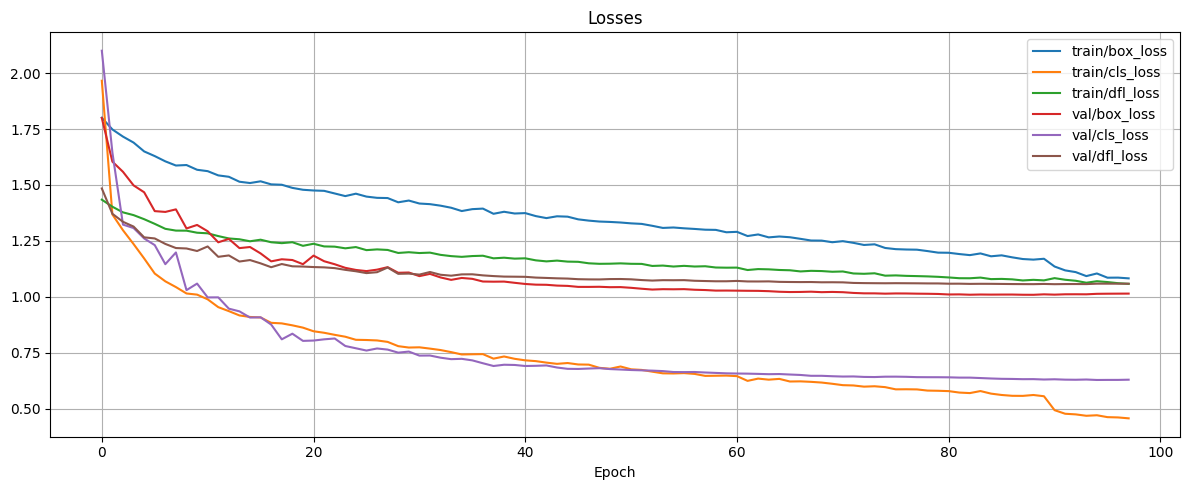

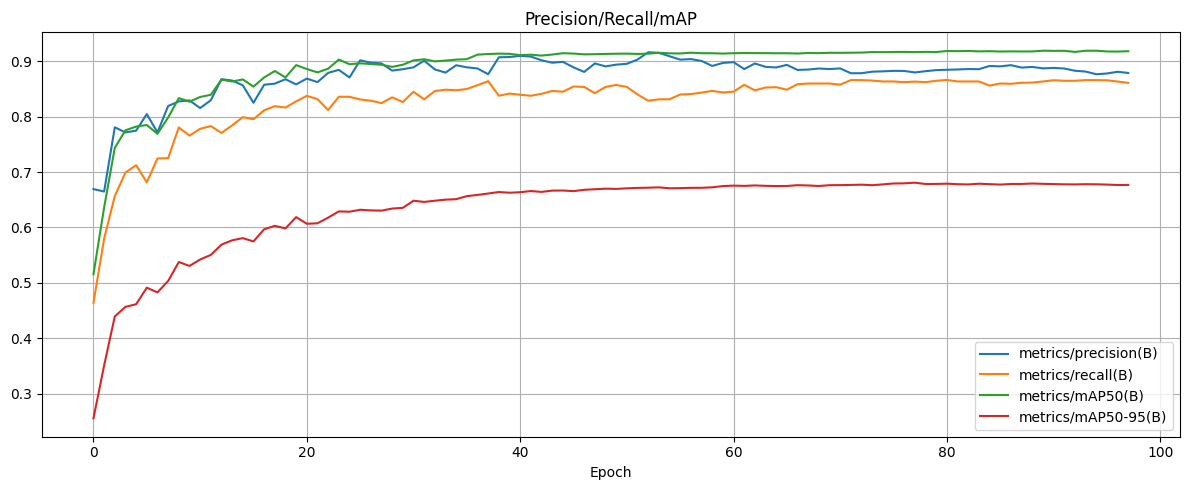

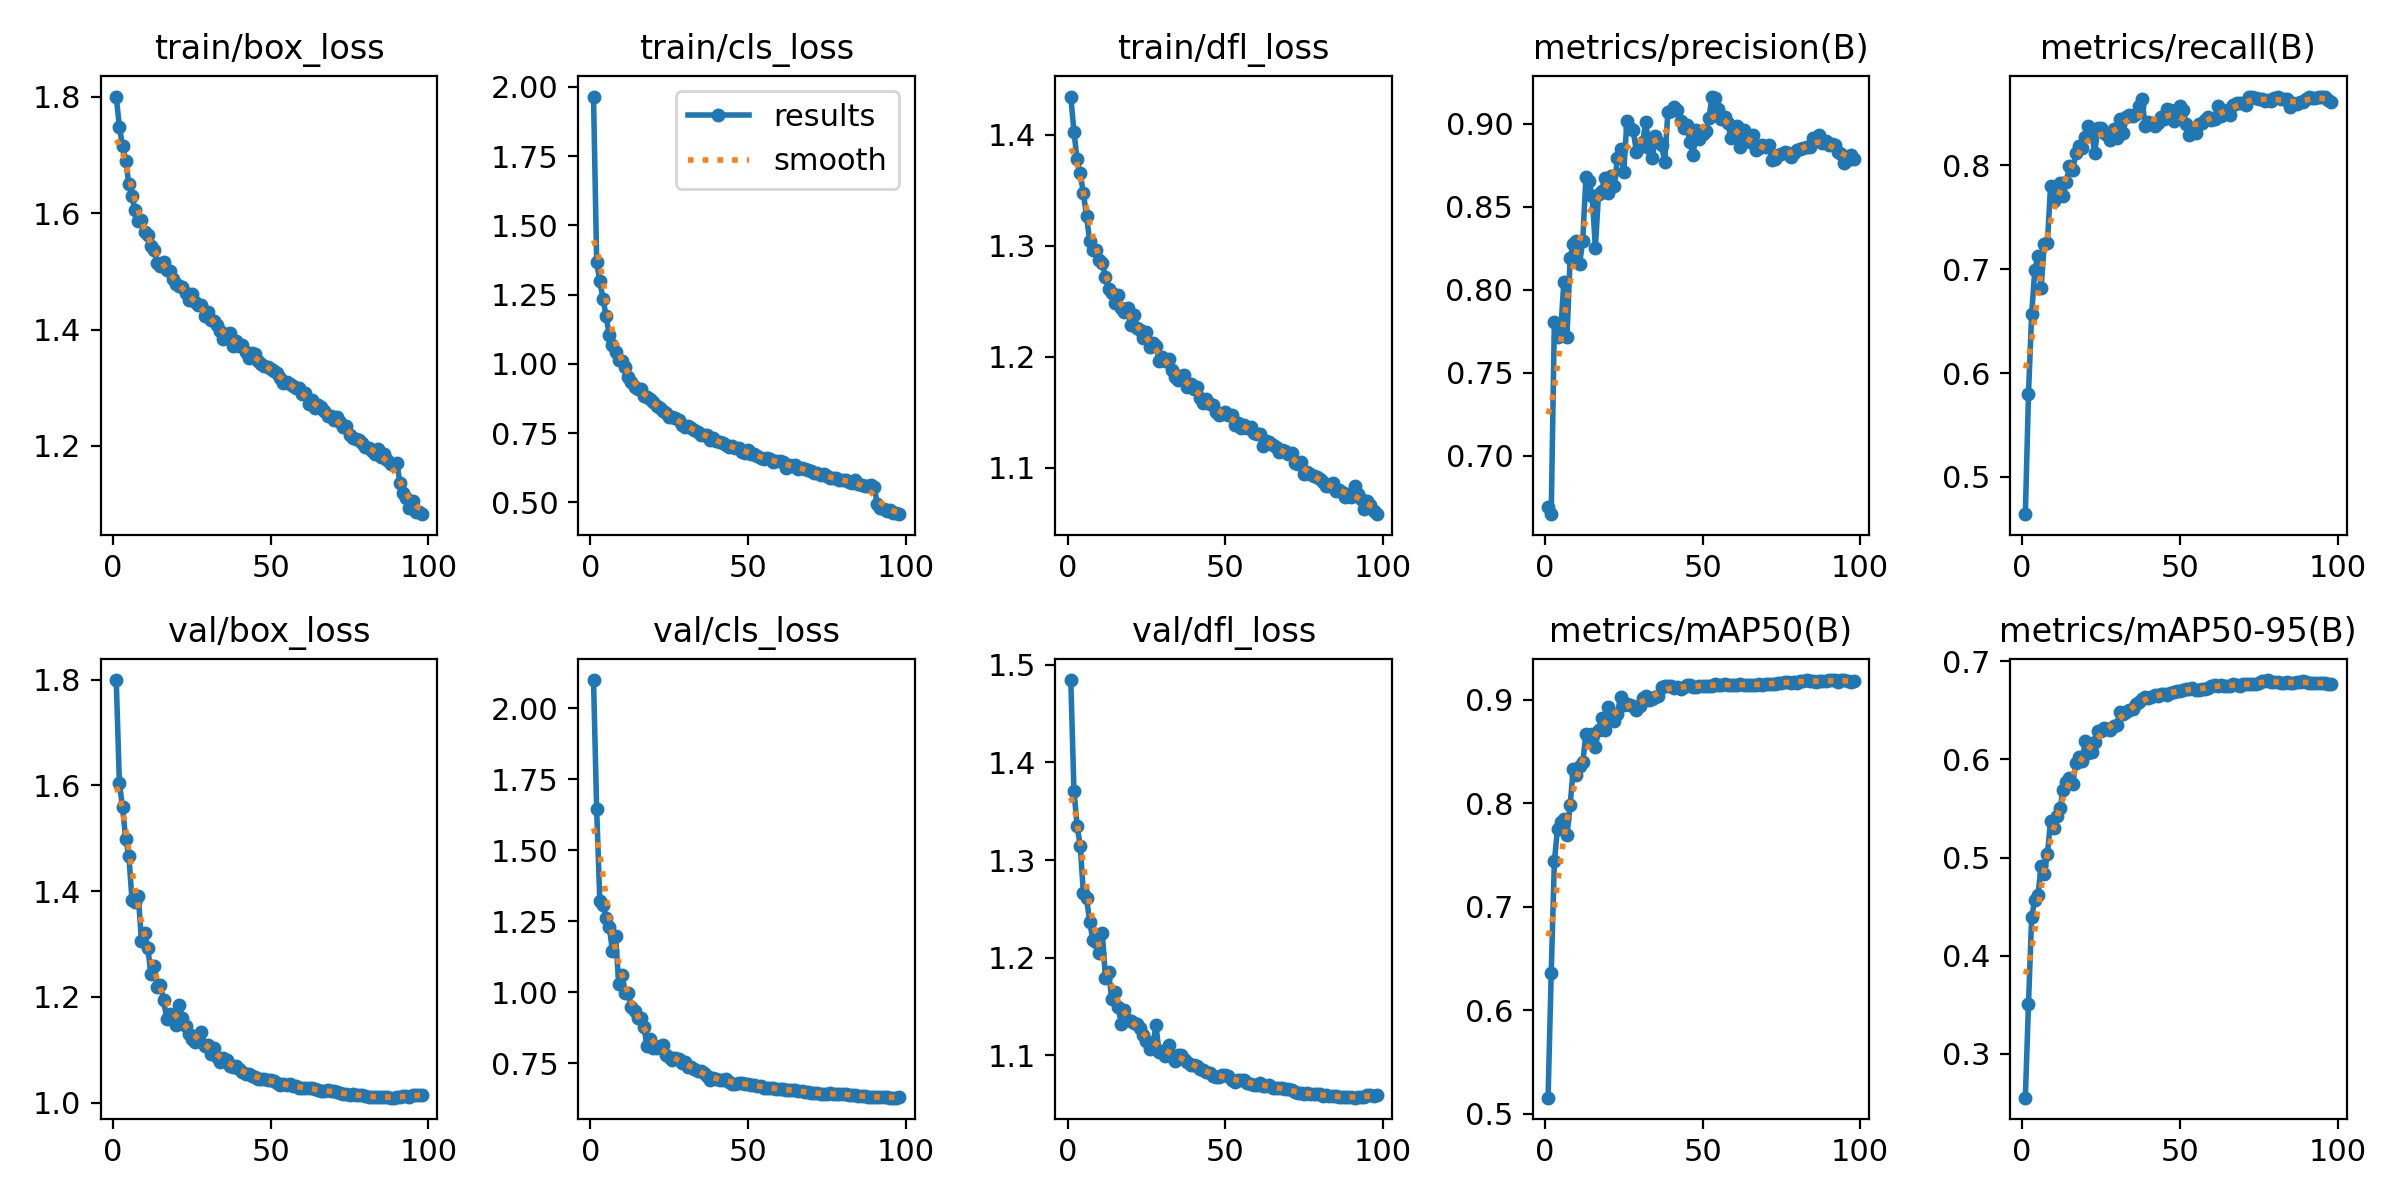

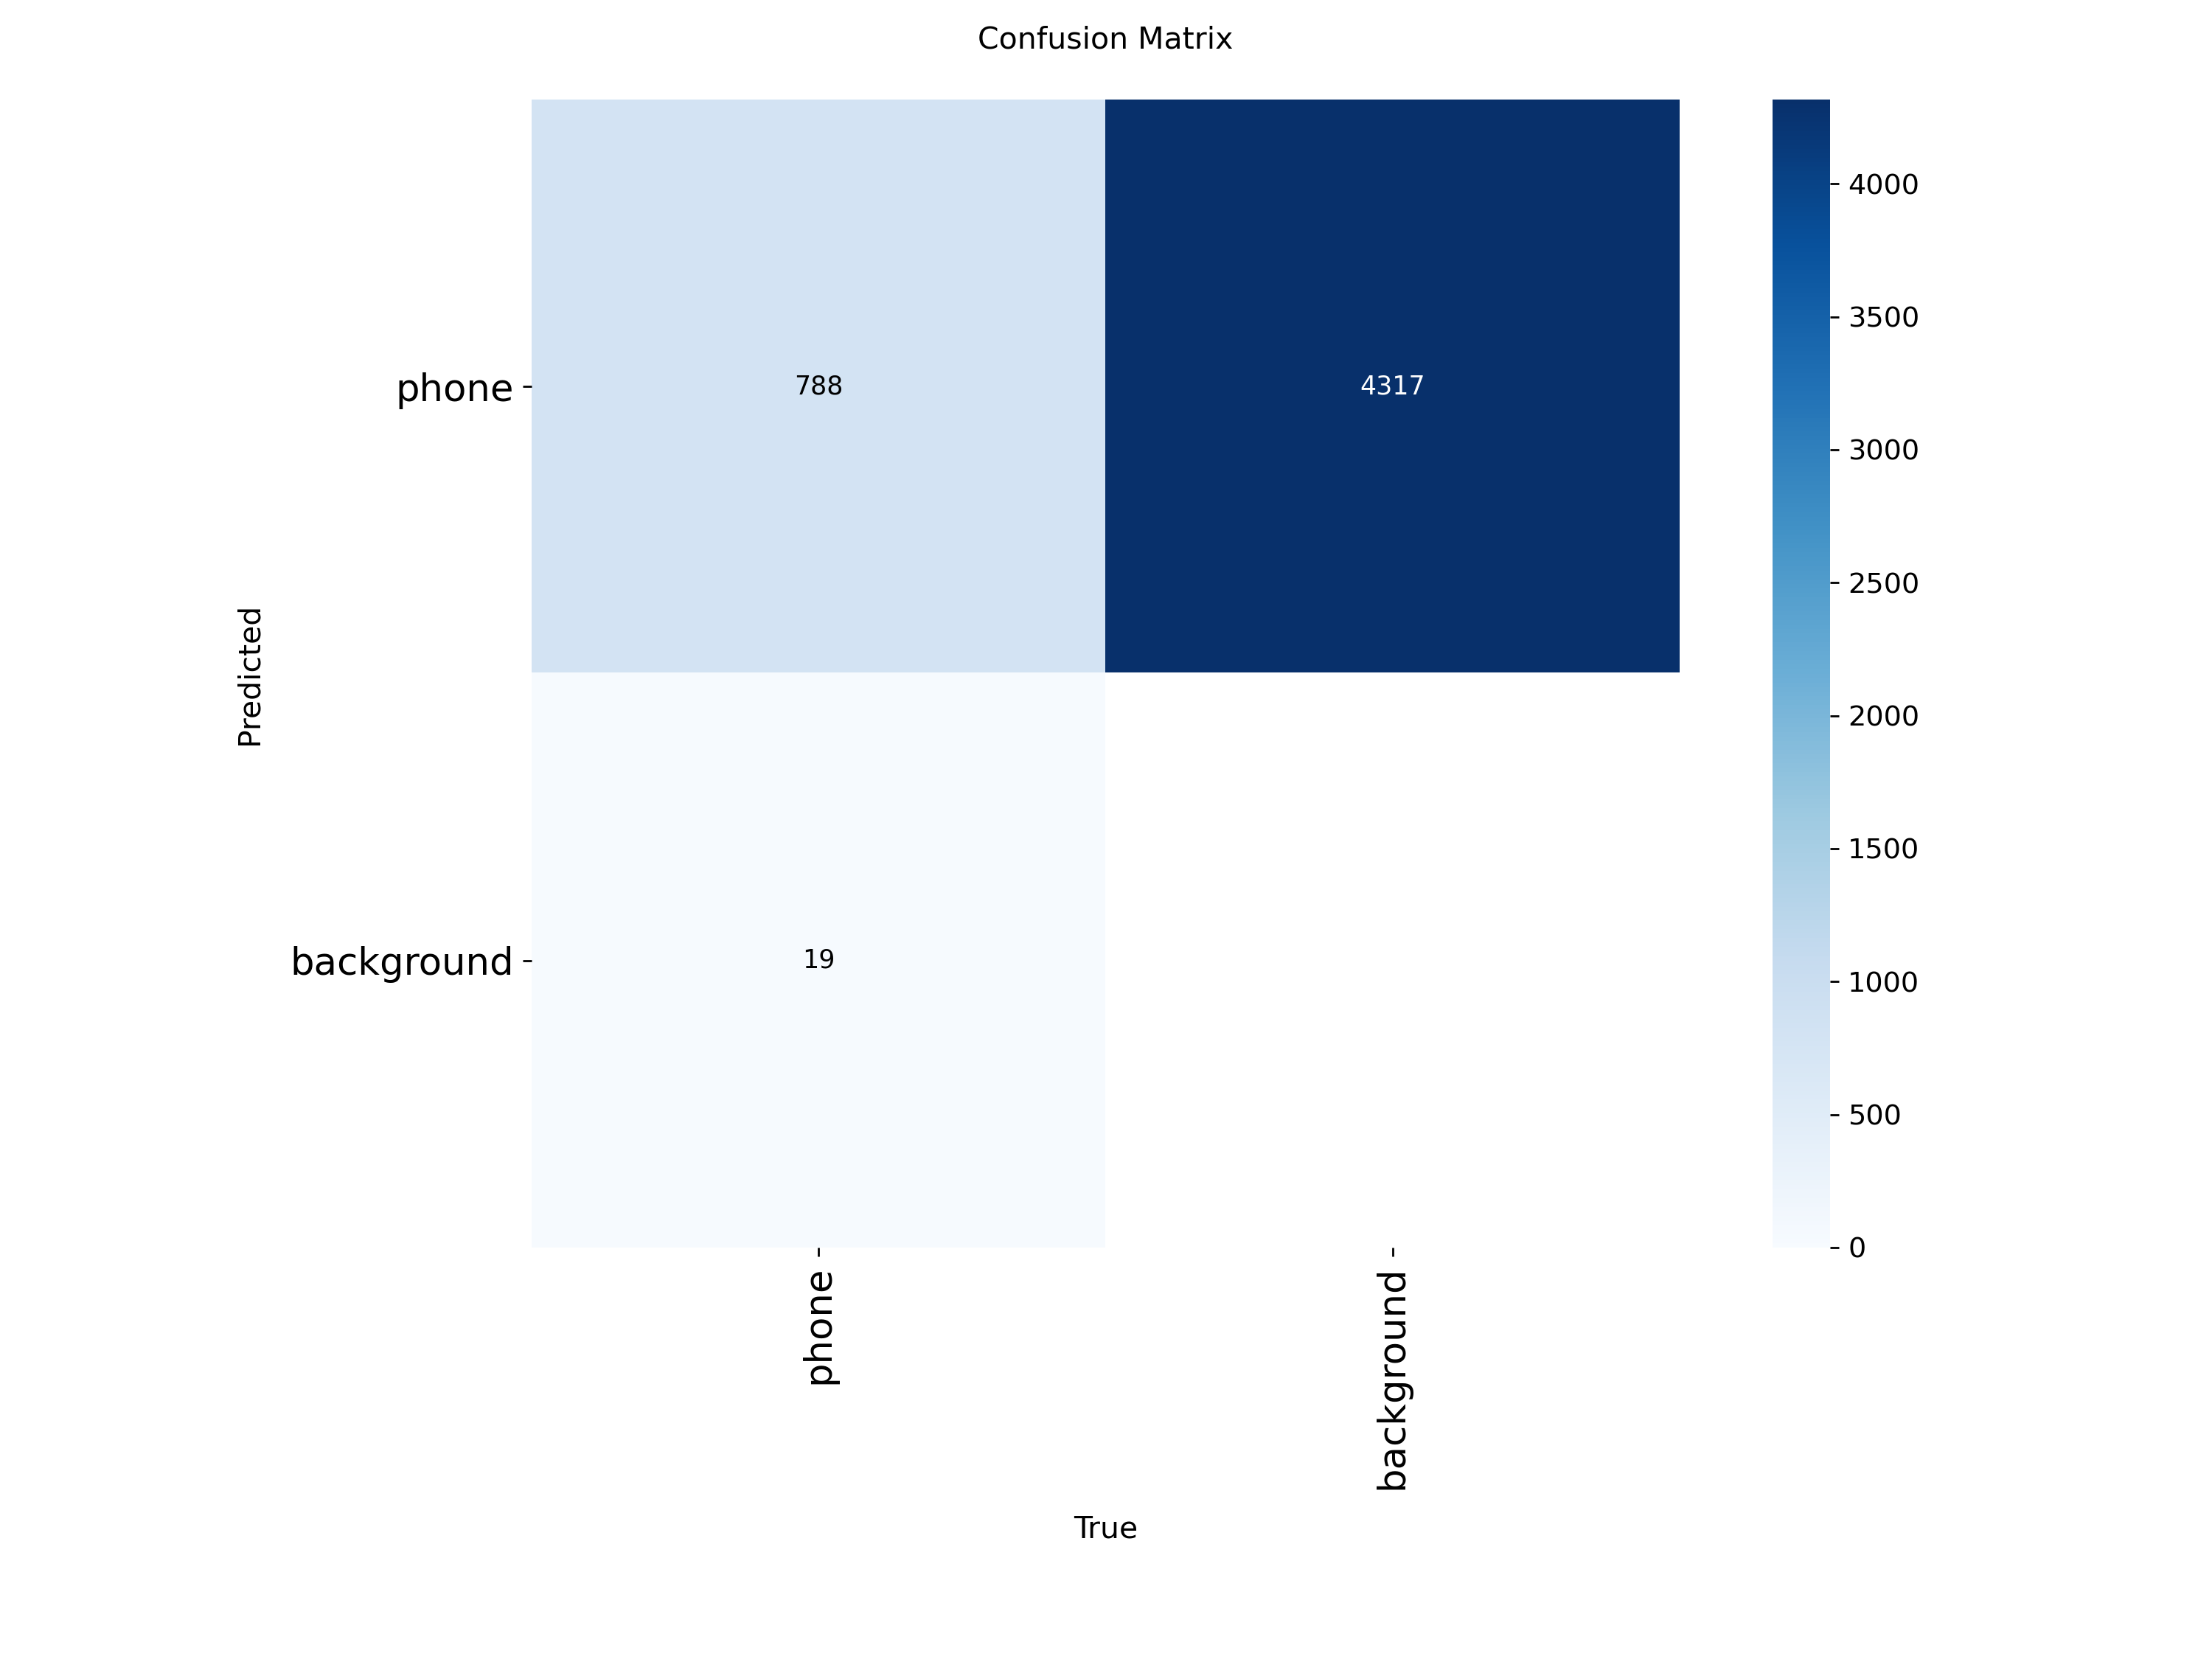

In [6]:
from IPython.display import display, Image as NotebookImage

csv_path = TRAIN_RUN_DIR / 'results.csv'
if csv_path.is_file():
    history = pd.read_csv(csv_path)
    display(history.tail(10))
    loss_cols = [c for c in ('train/box_loss','train/cls_loss','train/dfl_loss','val/box_loss','val/cls_loss','val/dfl_loss') if c in history]
    metric_cols = [c for c in ('metrics/precision(B)','metrics/recall(B)','metrics/mAP50(B)','metrics/mAP50-95(B)') if c in history]
    if loss_cols:
        history[loss_cols].plot(figsize=(12,5), grid=True, title='Losses')
        plt.xlabel('Epoch'); plt.tight_layout(); plt.show()
    if metric_cols:
        history[metric_cols].plot(figsize=(12,5), grid=True, title='Precision/Recall/mAP')
        plt.xlabel('Epoch'); plt.tight_layout(); plt.show()
else:
    print('Warning: results.csv was not found.')

for plot in (TRAIN_RUN_DIR / 'results.png', TRAIN_RUN_DIR / 'confusion_matrix.png'):
    if plot.is_file():
        display(NotebookImage(filename=str(plot)))
    else:
        print('Warning: missing:', plot)


## 6. Validation evaluation and model selection
The best checkpoint is assessed on the validation split. This result is used for model selection.

In [7]:
BEST_CHECKPOINT = TRAIN_RUN_DIR / 'weights' / 'best.pt'
LAST_CHECKPOINT = TRAIN_RUN_DIR / 'weights' / 'last.pt'
for p in (BEST_CHECKPOINT, LAST_CHECKPOINT):
    if not p.is_file():
        raise FileNotFoundError(p)

selected_model = YOLO(str(BEST_CHECKPOINT))
validation_metrics = selected_model.val(
    data=str(DATA_YAML), split='val', imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE, device=DEVICE, workers=NUM_WORKERS,
    plots=True, verbose=True,
)
validation_dict = getattr(validation_metrics, 'results_dict', {})
print('Validation metrics:', validation_dict)


Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 73.3±45.2 MB/s, size: 39.2 KB)
val: Scanning /kaggle/input/datasets/mohamedmagdyrizk/phone-detection-dataset/phone_detection/labels/val... 1730 images, 935 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1730/1730 844.4it/s 2.0s
val: /kaggle/input/datasets/mohamedmagdyrizk/phone-detection-dataset/phone_detection/images/val/YtgICLV3xln6Mj9P1adyUouF0As8JepX.jpg: 1 duplicate labels removed
val: /kaggle/input/datasets/mohamedmagdyrizk/phone-detection-dataset/phone_detection/images/val/w4YLCNeFZMTHdXK6oaWr9gbmxinkA0yD.jpg: 1 duplicate labels removed
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/mohamedmagdyrizk/phone-detection-dataset/phone_detection/labels is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-

## 7. Test-set evaluation — after model selection
This test evaluation is performed once after training/model selection. Test data is not used for tuning.

In [8]:
test_metrics = selected_model.val(
    data=str(DATA_YAML), split='test', imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE, device=DEVICE, workers=NUM_WORKERS,
    plots=True, verbose=True,
)
test_dict = getattr(test_metrics, 'results_dict', {})
print('Test metrics:', test_dict)


Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.4±0.1 ms, read: 0.6±0.4 MB/s, size: 33.1 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/input/datasets/mohamedmagdyrizk/phone-detection-dataset/phone_detection/labels/test... 2349 images, 1247 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2349/2349 34.8it/s 1:07
val: /kaggle/input/datasets/mohamedmagdyrizk/phone-detection-dataset/phone_detection/images/test/01gA2hbj9WaVZ3SXl7x5ovfriBQ6YFyn.jpg: 1 duplicate labels removed
val: /kaggle/input/datasets/mohamedmagdyrizk/phone-detection-dataset/phone_detection/images/test/5td4yijCnoevGPB3W9gcTNFSp7bMOD6q.jpg: 1 duplicate labels removed
val: /kaggle/input/datasets/mohamedmagdyrizk/phone-detection-dataset/phone_detecti

## 8. Representative test inference
The configurable threshold is used to find correct detections, missed detections, false positives, and images with no phone.

In [9]:
CONFIDENCE_THRESHOLD = 0.25
TEST_IMAGE_DIR = split_paths['test']
TEST_LABEL_DIR = DATASET_ROOT / 'labels' / 'test'


def read_gt(image_path):
    label = TEST_LABEL_DIR / f'{image_path.stem}.txt'
    result = []
    if not label.is_file():
        return result
    image = cv2.imread(str(image_path))
    if image is None:
        return result
    h, w = image.shape[:2]
    for line in label.read_text(encoding='utf-8').splitlines():
        fields = line.split()
        if len(fields) != 5:
            continue
        try:
            class_id, cx, cy, bw, bh = int(fields[0]), *map(float, fields[1:])
        except (ValueError, TypeError):
            continue
        if class_id == 0:
            result.append(np.array([(cx-bw/2)*w,(cy-bh/2)*h,(cx+bw/2)*w,(cy+bh/2)*h]))
    return result


def iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    union = area_a + area_b - inter
    return inter / union if union else 0.0

categories = {'correct': [], 'missed': [], 'false_positive': [], 'no_phone': []}
for image_path in sorted(p for p in TEST_IMAGE_DIR.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS):
    gt = read_gt(image_path)
    result = selected_model.predict(source=str(image_path), imgsz=IMAGE_SIZE, conf=CONFIDENCE_THRESHOLD, device=DEVICE, verbose=False)[0]
    preds = [np.array(b.xyxy.cpu().numpy()[0], dtype=np.float32) for b in result.boxes]
    matched_gt = set()
    for pred in preds:
        for index, truth in enumerate(gt):
            if index not in matched_gt and iou(pred, truth) >= 0.5:
                matched_gt.add(index)
                break
    if gt and len(matched_gt) == len(gt):
        categories['correct'].append(image_path)
    elif gt:
        categories['missed'].append(image_path)
    elif preds:
        categories['false_positive'].append(image_path)
    else:
        categories['no_phone'].append(image_path)
    if all(categories.values()) and sum(map(len, categories.values())) >= 8:
        break
for name, paths in categories.items():
    print(name, len(paths))


correct 3
missed 1
false_positive 1
no_phone 3


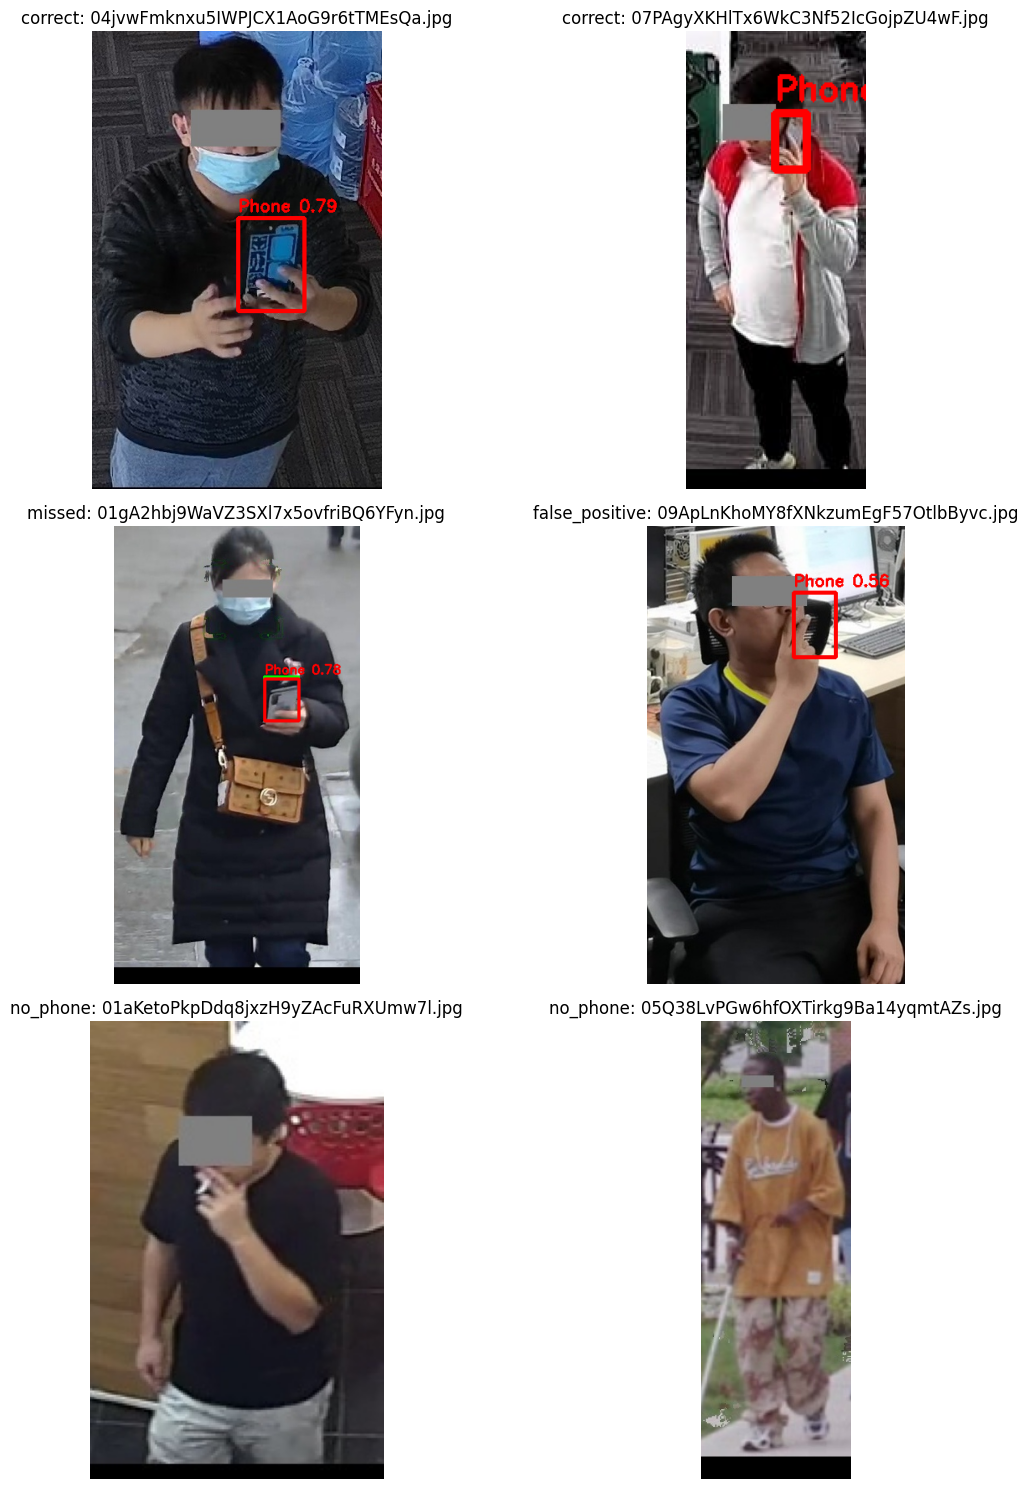

In [10]:
representative = []
for paths in categories.values():
    representative.extend(paths[:2])

if representative:
    cols = 2
    rows = int(np.ceil(len(representative) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(14, 5*rows))
    axes = np.asarray(axes).reshape(-1)
    for ax, image_path in zip(axes, representative):
        bgr = cv2.imread(str(image_path))
        if bgr is None:
            ax.axis('off'); continue
        annotated = cv2.cvtColor(bgr.copy(), cv2.COLOR_BGR2RGB)
        for truth in read_gt(image_path):
            x1,y1,x2,y2 = truth.astype(int)
            cv2.rectangle(annotated,(x1,y1),(x2,y2),(0,255,0),2)
        result = selected_model.predict(source=str(image_path), imgsz=IMAGE_SIZE, conf=CONFIDENCE_THRESHOLD, device=DEVICE, verbose=False)[0]
        for box in result.boxes:
            x1,y1,x2,y2 = box.xyxy.cpu().numpy()[0].astype(int)
            confidence = box.conf.item()
            cv2.rectangle(annotated,(x1,y1),(x2,y2),(255,0,0),3)
            cv2.putText(annotated,f'Phone {confidence:.2f}',(x1,max(18,y1-8)),cv2.FONT_HERSHEY_SIMPLEX,0.65,(255,0,0),2)
        category = next((name for name, paths in categories.items() if image_path in paths), 'test')
        ax.imshow(annotated); ax.set_title(f'{category}: {image_path.name}'); ax.axis('off')
    for ax in axes[len(representative):]:
        ax.axis('off')
    plt.tight_layout(); plt.show()
else:
    print('No representative test images were categorized.')


## 9. Save final artifacts
Kaggle: `/kaggle/working/artifacts/phone_detection/`. Local: `artifacts/phone_detection/`.
The complete artifact directory must be downloaded after a Kaggle run.

In [11]:
import shutil
import json

ARTIFACT_ROOT = Path('/kaggle/working/artifacts/phone_detection') if IS_KAGGLE else OUTPUT_ROOT / 'artifacts' / 'phone_detection'
weights_dir = ARTIFACT_ROOT / 'weights'
results_dir = ARTIFACT_ROOT / 'results'
inference_dir = ARTIFACT_ROOT / 'inference_examples'
for directory in (weights_dir, results_dir, inference_dir):
    directory.mkdir(parents=True, exist_ok=True)

shutil.copy2(BEST_CHECKPOINT, weights_dir / 'best.pt')
shutil.copy2(LAST_CHECKPOINT, weights_dir / 'last.pt')
for name in ('results.csv', 'confusion_matrix.png', 'results.png'):
    source = TRAIN_RUN_DIR / name
    if source.is_file():
        shutil.copy2(source, results_dir / name)
    else:
        print('Warning: missing training output:', source)

metrics = {
    'model': MODEL_NAME,
    'image_size': IMAGE_SIZE,
    'validation': validation_dict,
    'test': test_dict,
    'confidence_threshold': CONFIDENCE_THRESHOLD,
}
(results_dir / 'evaluation_metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')

for index, image_path in enumerate(representative[:8], 1):
    bgr = cv2.imread(str(image_path))
    if bgr is None:
        continue
    annotated = cv2.cvtColor(bgr.copy(), cv2.COLOR_BGR2RGB)
    for truth in read_gt(image_path):
        x1,y1,x2,y2 = truth.astype(int)
        cv2.rectangle(annotated,(x1,y1),(x2,y2),(0,255,0),2)
    result = selected_model.predict(source=str(image_path), imgsz=IMAGE_SIZE, conf=CONFIDENCE_THRESHOLD, device=DEVICE, verbose=False)[0]
    for box in result.boxes:
        x1,y1,x2,y2 = box.xyxy.cpu().numpy()[0].astype(int)
        conf = box.conf.item()
        cv2.rectangle(annotated,(x1,y1),(x2,y2),(255,0,0),3)
        cv2.putText(annotated,f'Phone {conf:.2f}',(x1,max(18,y1-8)),cv2.FONT_HERSHEY_SIMPLEX,0.65,(255,0,0),2)
    category = next((name for name, paths in categories.items() if image_path in paths), 'test')
    cv2.imwrite(str(inference_dir / f'{index:02d}_{category}_{image_path.name}'), cv2.cvtColor(annotated, cv2.COLOR_RGB2BGR))

info_lines = [
    'DriveSense AI - Phone Detection Model',
    '===================================',
    f'Model: {MODEL_NAME}',
    f'Image size: {IMAGE_SIZE}',
    f'Epochs: {EPOCHS}',
    f'Batch size: {BATCH_SIZE}',
    f'Optimizer: {OPTIMIZER}',
    f'Learning rate: {LEARNING_RATE}',
    f'Patience: {PATIENCE}',
    f'Seed: {RANDOM_SEED}',
    f'Workers: {NUM_WORKERS}',
    f'Device: {DEVICE}',
    f'Dataset yaml: {DATA_YAML}',
    f'Dataset root: {DATASET_ROOT}',
    'Class 0: phone',
    '', 'Validation metrics:',
]
info_lines.extend(f'{key}: {value}' for key, value in validation_dict.items())
info_lines.extend(['', 'Test metrics:'])
info_lines.extend(f'{key}: {value}' for key, value in test_dict.items())
(ARTIFACT_ROOT / 'model_info.txt').write_text('\n'.join(info_lines), encoding='utf-8')

print('Artifacts:', ARTIFACT_ROOT)
for artifact in sorted(p for p in ARTIFACT_ROOT.rglob('*') if p.is_file()):
    print('-', artifact.relative_to(ARTIFACT_ROOT))


Artifacts: /kaggle/working/artifacts/phone_detection
- inference_examples/01_correct_04jvwFmknxu5IWPJCX1AoG9r6tTMEsQa.jpg
- inference_examples/02_correct_07PAgyXKHlTx6WkC3Nf52IcGojpZU4wF.jpg
- inference_examples/03_missed_01gA2hbj9WaVZ3SXl7x5ovfriBQ6YFyn.jpg
- inference_examples/04_false_positive_09ApLnKhoMY8fXNkzumEgF57OtlbByvc.jpg
- inference_examples/05_no_phone_01aKetoPkpDdq8jxzH9yZAcFuRXUmw7l.jpg
- inference_examples/06_no_phone_05Q38LvPGw6hfOXTirkg9Ba14yqmtAZs.jpg
- model_info.txt
- results/confusion_matrix.png
- results/evaluation_metrics.json
- results/results.csv
- results/results.png
- weights/best.pt
- weights/last.pt


## 10. Reload later and Kaggle persistence

```python
from ultralytics import YOLO
model = YOLO('artifacts/phone_detection/weights/best.pt')
predictions = model.predict(source='image.jpg', imgsz=640, conf=0.25)
```

Kaggle runtime storage is temporary. Download the complete `artifacts/phone_detection/` directory after execution. The final model must not live only in temporary Kaggle storage or inside the dataset directory.